# TabR datatest-fix event-level inference — 7 models

Input: `output/apex/datatest-fix/features/datatest-fix/poc_abs_test.xlsx`

Output: clear event-level ranking, best model table, visual confusion matrices, Excel/CSV artifacts.


In [1]:
import gc
import json
import os
import re
import sys
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from IPython.display import Markdown, display
from scipy.special import expit
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, precision_recall_fscore_support

sns.set_theme(style='whitegrid')
ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

TABR_ROOT = ROOT / 'third_party' / 'tabular-dl-tabr-official'
os.environ['PROJECT_DIR'] = str(TABR_ROOT)
if str(TABR_ROOT) not in sys.path:
    sys.path.append(str(TABR_ROOT))

import lib
from bin.tabr import Model

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
EXP_ROOT = TABR_ROOT / 'exp' / 'tabr'
DATA_ROOT = TABR_ROOT / 'data'
FEATURES_PATH = ROOT / 'output/apex/datatest-fix/features/datatest-fix/poc_abs_test.xlsx'
EVAL_ROOT = ROOT / 'output/apex/datatest-fix/event_level_7models_report'
CM_ROOT = EVAL_ROOT / 'confusion_matrices'
EVAL_ROOT.mkdir(parents=True, exist_ok=True)
CM_ROOT.mkdir(parents=True, exist_ok=True)

TOP_K = 3
EVENT_METHODS = ['mean', 'top3_mean', 'p90', 'max']
THRESHOLDS = np.round(np.arange(0.40, 0.651, 0.025), 3)
PRIMARY_SORT = ['macro_f1', 'balanced_accuracy', 'accuracy', 'recall_tinggi']
FPS = 25
BATCH_SIZE = 128 if device.type == 'cuda' else 512
MAX_WORKERS = 1 if device.type == 'cuda' else 3

MODEL_SPECS = [
    {'label': 'ORI | baseline event model', 'exp_name': 'convat_apex_anxiety', 'mode': 'baseline', 'variant': 'original'},
    {'label': 'ORI | qholdout q123-q4-q5', 'exp_name': 'convat_apex_anxiety_qholdout_q123_q4_q5', 'mode': 'qholdout', 'variant': 'original'},
    {'label': 'ORI | qwalk q12-q3-q4', 'exp_name': 'convat_apex_anxiety_qwalk_q12_q3_q4', 'mode': 'qwalkforward', 'variant': 'original'},
    {'label': 'ORI | qwalk q123-q4-q5', 'exp_name': 'convat_apex_anxiety_qwalk_q123_q4_q5', 'mode': 'qwalkforward', 'variant': 'original'},
    {'label': 'FIX | qholdout q123-q4-q5', 'exp_name': 'convat_apex_anxiety_qholdout_q123_q4_q5_fix', 'mode': 'qholdout', 'variant': 'fix'},
    {'label': 'FIX | qwalk q12-q3-q4', 'exp_name': 'convat_apex_anxiety_qwalk_q12_q3_q4_fix', 'mode': 'qwalkforward', 'variant': 'fix'},
    {'label': 'FIX | qwalk q123-q4-q5', 'exp_name': 'convat_apex_anxiety_qwalk_q123_q4_q5_fix', 'mode': 'qwalkforward', 'variant': 'fix'},
]
display(pd.DataFrame(MODEL_SPECS))
print(f'ROOT={ROOT}')
print(f'Device={device} batch_size={BATCH_SIZE} max_workers={MAX_WORKERS}')
print(f'Features={FEATURES_PATH}')



,label,exp_name,mode,variant
0,ORI | baseline event model,convat_apex_anxiety,baseline,original
1,ORI | qholdout q123-q4-q5,convat_apex_anxiety_qholdout_q123_q4_q5,qholdout,original
2,ORI | qwalk q12-q3-q4,convat_apex_anxiety_qwalk_q12_q3_q4,qwalkforward,original
3,ORI | qwalk q123-q4-q5,convat_apex_anxiety_qwalk_q123_q4_q5,qwalkforward,original
4,FIX | qholdout q123-q4-q5,convat_apex_anxiety_qholdout_q123_q4_q5_fix,qholdout,fix
5,FIX | qwalk q12-q3-q4,convat_apex_anxiety_qwalk_q12_q3_q4_fix,qwalkforward,fix
6,FIX | qwalk q123-q4-q5,convat_apex_anxiety_qwalk_q123_q4_q5_fix,qwalkforward,fix


ROOT=/home/ryuko/skripsi/Skripsi/Convat-1st
Device=cuda batch_size=128 max_workers=1
Features=/home/ryuko/skripsi/Skripsi/Convat-1st/output/apex/datatest-fix/features/datatest-fix/poc_abs_test.xlsx


In [2]:
def label_to_int(label: str) -> int:
    key = str(label).strip().lower().replace('-', '_')
    return 1 if key in {'anxiety_tinggi', 'anxiety', 'tinggi', '1'} else 0


def int_to_label(value: int) -> str:
    return 'anxiety_tinggi' if int(value) == 1 else 'anxiety_rendah'


def participant_base(value: str) -> str:
    return re.sub(r'_\d+$', '', str(value))


def load_features(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(path)
    df = pd.read_excel(path)
    if 'date' not in df.columns:
        df['date'] = path.parent.name
    required = ['label', 'participant_raw', 'question', 'sample', 'event_clip', 'event_no', 'frame']
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise KeyError(f'Missing required columns: {missing}')
    df = df[df['label'].isin(['anxiety_tinggi', 'anxiety_rendah'])].copy()
    df['participant_base'] = df['participant_raw'].map(participant_base)
    df['true_label'] = df['label'].map(label_to_int).astype(int)
    df['event_key'] = (
        df['date'].astype(str) + '|' + df['participant_raw'].astype(str) + '|' + df['question'].astype(str) + '|' +
        df['sample'].astype(str) + '|' + df['event_clip'].astype(str) + '|' + df['event_no'].astype(str)
    )
    df['kode_event'] = df['participant_raw'].astype(str) + ' / ' + df['question'].astype(str) + ' / ' + df['event_clip'].astype(str)
    return df

frame_df = load_features(FEATURES_PATH)
event_overview_df = (
    frame_df.groupby('event_key', sort=False)
    .agg(
        kode_event=('kode_event', 'first'),
        participant=('participant_raw', 'first'),
        question=('question', 'first'),
        label=('label', 'first'),
        n_frames=('frame', 'count'),
    )
    .reset_index(drop=True)
)
event_overview_df.insert(0, 'No', np.arange(1, len(event_overview_df) + 1))
event_overview_df['duration_sec'] = event_overview_df['n_frames'] / FPS

print('frames:', len(frame_df))
print('events:', frame_df['event_key'].nunique())
print('subjects:', frame_df['participant_base'].nunique())
print('label events:', event_overview_df['label'].value_counts().to_dict())
display(event_overview_df.head(20))


frames: 2937
events: 231
subjects: 12
label events: {'anxiety_rendah': 146, 'anxiety_tinggi': 85}


,No,kode_event,participant,question,label,n_frames,duration_sec
0,1,abim_mustawa_1776388618012 / q1 / event_00055-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,12,0.48
1,2,abim_mustawa_1776388618012 / q1 / event_00076-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,18,0.72
2,3,abim_mustawa_1776388618012 / q1 / event_00130-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,12,0.48
3,4,abim_mustawa_1776388618012 / q1 / event_00149-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,20,0.80
4,5,abim_mustawa_1776388618012 / q1 / event_00295-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,14,0.56
5,6,abim_mustawa_1776388618012 / q2 / event_00089-...,abim_mustawa_1776388618012,q2,anxiety_tinggi,9,0.36
6,7,abim_mustawa_1776388618012 / q2 / event_00119-...,abim_mustawa_1776388618012,q2,anxiety_tinggi,11,0.44
7,8,abim_mustawa_1776388618012 / q2 / event_00149-...,abim_mustawa_1776388618012,q2,anxiety_tinggi,17,0.68
8,9,abim_mustawa_1776388618012 / q3 / event_00068-...,abim_mustawa_1776388618012,q3,anxiety_tinggi,12,0.48
9,10,abim_mustawa_1776388618012 / q3 / event_00096-...,abim_mustawa_1776388618012,q3,anxiety_tinggi,13,0.52


In [3]:
def load_best_seed_report(exp_name: str) -> tuple[int, dict, Path]:
    eval_dir = EXP_ROOT / exp_name / '0-evaluation'
    rows = []
    for run_dir in sorted([x for x in eval_dir.iterdir() if x.is_dir() and x.name.isdigit()]):
        report_path = run_dir / 'report.json'
        if report_path.exists():
            report = json.loads(report_path.read_text())
            rows.append((int(run_dir.name), report, run_dir))
    if not rows:
        raise FileNotFoundError(f'No report.json found: {eval_dir}')
    return max(rows, key=lambda x: x[1]['metrics']['val']['score'])


def load_run_config(exp_name: str, best_seed: int, report: dict) -> dict:
    seed_toml = EXP_ROOT / exp_name / f'{best_seed}.toml'
    if seed_toml.exists():
        return lib.load_config(seed_toml)
    if 'config' in report:
        return report['config']
    tuning_toml = EXP_ROOT / exp_name / '0-tuning.toml'
    if tuning_toml.exists():
        return lib.load_config(tuning_toml)
    raise FileNotFoundError(f'No config for {exp_name}')


def resolve_data_dir(data_path: str) -> Path:
    return DATA_ROOT / data_path.removeprefix(':data/') if data_path.startswith(':data/') else Path(data_path)


def load_model_bundle(exp_name: str) -> dict:
    best_seed, report, best_run_dir = load_best_seed_report(exp_name)
    cfg = load_run_config(exp_name, best_seed, report)
    data_dir = resolve_data_dir(cfg['data']['path'])
    feature_cols = json.loads((data_dir / 'feature_cols.json').read_text())
    dataset = lib.build_dataset(**cfg['data']).to_torch(device)
    model = Model(
        n_num_features=dataset.n_num_features,
        n_bin_features=dataset.n_bin_features,
        cat_cardinalities=dataset.cat_cardinalities(),
        n_classes=dataset.n_classes(),
        **cfg['model'],
    ).to(device)
    checkpoint = lib.load_checkpoint(best_run_dir)
    model.load_state_dict(checkpoint['model'])
    model.eval()
    candidate_x = {key[2:]: dataset.data[key]['train'] for key in dataset.data if key.startswith('X_')}
    return {
        'model': model,
        'candidate_x': candidate_x,
        'candidate_y': dataset.Y['train'],
        'feature_cols': feature_cols,
        'context_size': cfg['context_size'],
        'best_seed': best_seed,
        'data_path': cfg['data']['path'],
    }


def release_model_bundle(bundle: dict) -> None:
    del bundle
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


In [4]:
@torch.inference_mode()
def predict_frame_probs(bundle: dict, df: pd.DataFrame, batch_size: int = BATCH_SIZE) -> np.ndarray:
    feature_cols = bundle['feature_cols']
    missing = [c for c in feature_cols if c not in df.columns]
    if missing:
        raise KeyError(f'Missing feature cols: {missing[:20]}')
    x_np = df[feature_cols].to_numpy(dtype=np.float32)
    probs = []
    total = len(x_np)
    for start in range(0, total, batch_size):
        xb = torch.as_tensor(x_np[start:start + batch_size], device=device)
        try:
            logits = bundle['model'](
                x_={'num': xb}, y=None,
                candidate_x_=bundle['candidate_x'], candidate_y=bundle['candidate_y'],
                context_size=bundle['context_size'], is_train=False,
            ).squeeze(-1).detach().cpu().numpy()
            probs.extend(expit(logits).astype(float).tolist())
        except RuntimeError as exc:
            if xb.shape[0] == 1:
                raise
            # fallback aman kalau batch TabR/FAISS bermasalah
            for i in range(xb.shape[0]):
                logit = bundle['model'](
                    x_={'num': xb[i:i + 1]}, y=None,
                    candidate_x_=bundle['candidate_x'], candidate_y=bundle['candidate_y'],
                    context_size=bundle['context_size'], is_train=False,
                ).squeeze(-1).item()
                probs.append(float(expit(logit)))
        if start == 0 or start + batch_size >= total or ((start // batch_size) % 10 == 0):
            print(f'  predicted {min(start + batch_size, total)}/{total} frames')
    return np.asarray(probs, dtype=float)


def aggregate_probs(values, method: str, top_k: int = TOP_K) -> float:
    arr = np.asarray(list(values), dtype=float)
    if len(arr) == 0:
        return np.nan
    if method == 'mean':
        return float(np.mean(arr))
    if method == 'max':
        return float(np.max(arr))
    if method == 'p90':
        return float(np.quantile(arr, 0.90))
    if method == 'top3_mean':
        return float(np.mean(np.sort(arr)[-min(top_k, len(arr)):]))
    raise ValueError(method)


In [5]:
def make_event_predictions(work: pd.DataFrame, spec: dict, method: str, threshold: float) -> pd.DataFrame:
    rows = []
    meta_cols = ['event_key', 'kode_event', 'label', 'true_label', 'participant_base', 'participant_raw', 'question', 'sample', 'event_clip', 'event_no']
    for _event_key, g in work.groupby('event_key', sort=False):
        first = g.iloc[0]
        prob = aggregate_probs(g['prob_anxiety_tinggi'], method)
        row = {col: first[col] for col in meta_cols if col in g.columns}
        row.update({
            'model_label': spec['label'],
            'exp_name': spec['exp_name'],
            'mode': spec['mode'],
            'aggregation': method,
            'threshold': float(threshold),
            'agg_prob_anxiety_tinggi': prob,
            'pred_label': int(prob >= threshold),
            'n_frames': len(g),
        })
        rows.append(row)
    return pd.DataFrame(rows)


def metrics_dict(df: pd.DataFrame, spec: dict, method: str, threshold: float) -> dict:
    y_true = df['true_label'].astype(int).to_numpy()
    y_pred = df['pred_label'].astype(int).to_numpy()
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    precision_macro, recall_macro, macro_f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    per_prec, per_rec, per_f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1], zero_division=0)
    return {
        'model': spec['label'], 'variant': spec.get('variant', ''), 'exp_name': spec['exp_name'], 'mode': spec['mode'],
        'aggregation': method, 'threshold': float(threshold), 'n_events': len(df),
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'balanced_accuracy': float(balanced_accuracy_score(y_true, y_pred)),
        'precision_macro': float(precision_macro), 'recall_macro': float(recall_macro), 'macro_f1': float(macro_f1),
        'precision_rendah': float(per_prec[0]), 'recall_rendah': float(per_rec[0]), 'f1_rendah': float(per_f1[0]),
        'precision_tinggi': float(per_prec[1]), 'recall_tinggi': float(per_rec[1]), 'f1_tinggi': float(per_f1[1]),
    }


def evaluate_grid(work: pd.DataFrame, spec: dict) -> tuple[pd.DataFrame, dict]:
    rows, predictions = [], {}
    for method in EVENT_METHODS:
        base = make_event_predictions(work, spec, method, threshold=0.5)
        probs = base['agg_prob_anxiety_tinggi'].to_numpy()
        for threshold in THRESHOLDS:
            pred_df = base.copy()
            pred_df['threshold'] = float(threshold)
            pred_df['pred_label'] = (probs >= float(threshold)).astype(int)
            rows.append(metrics_dict(pred_df, spec, method, float(threshold)))
            predictions[(method, float(threshold))] = pred_df
    return pd.DataFrame(rows), predictions


def choose_best(summary_df: pd.DataFrame) -> pd.Series:
    return summary_df.sort_values(PRIMARY_SORT, ascending=False).iloc[0]


def safe_name(value: str) -> str:
    return re.sub(r'[^A-Za-z0-9_.-]+', '_', str(value))



In [6]:
def plot_confusion(df: pd.DataFrame, title: str, path: Path):
    y_true = df['true_label'].astype(int).to_numpy()
    y_pred = df['pred_label'].astype(int).to_numpy()
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['pred rendah', 'pred tinggi'], yticklabels=['true rendah', 'true tinggi'], ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Aktual')
    plt.tight_layout()
    fig.savefig(path, dpi=170)
    plt.show()
    plt.close(fig)


def plot_best_model_grid(best_predictions_df: pd.DataFrame, best_metrics_df: pd.DataFrame):
    n = len(best_metrics_df)
    cols = 3
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 4.8, rows * 4.2))
    axes = np.asarray(axes).reshape(-1)
    for ax, (_, metric) in zip(axes, best_metrics_df.iterrows()):
        part = best_predictions_df[best_predictions_df['model_label'] == metric['model']]
        cm = confusion_matrix(part['true_label'].astype(int), part['pred_label'].astype(int), labels=[0, 1])
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                    xticklabels=['rendah', 'tinggi'], yticklabels=['rendah', 'tinggi'], ax=ax)
        ax.set_title(f"{metric['model']}\n{metric['aggregation']} thr={metric['threshold']:.3f} F1={metric['macro_f1']:.3f}")
        ax.set_xlabel('Prediksi')
        ax.set_ylabel('Aktual')
    for ax in axes[n:]:
        ax.axis('off')
    plt.tight_layout()
    path = CM_ROOT / 'confusion_matrix__best_all_models_grid.png'
    fig.savefig(path, dpi=180)
    plt.show()
    plt.close(fig)
    return path


def make_prediction_table(prediction_df: pd.DataFrame) -> pd.DataFrame:
    table = prediction_df[['kode_event', 'participant_raw', 'question', 'true_label', 'pred_label', 'agg_prob_anxiety_tinggi', 'n_frames']].copy()
    table.insert(0, 'No', np.arange(1, len(table) + 1))
    table['Label Aktual'] = table['true_label'].map(int_to_label)
    table['Label Prediksi'] = table['pred_label'].map(int_to_label)
    table['Status'] = np.where(table['true_label'] == table['pred_label'], 'Benar', 'Salah')
    return table.rename(columns={
        'kode_event': 'Kode Event', 'participant_raw': 'Participant', 'question': 'Question',
        'agg_prob_anxiety_tinggi': 'Prob Tinggi', 'n_frames': 'Jumlah Frame'
    })[['No', 'Kode Event', 'Participant', 'Question', 'Label Aktual', 'Label Prediksi', 'Prob Tinggi', 'Jumlah Frame', 'Status']]


In [7]:
def run_one_model(spec: dict) -> dict:
    print(f"START {spec['label']}")
    bundle = load_model_bundle(spec['exp_name'])
    print(f"  seed={bundle['best_seed']} features={len(bundle['feature_cols'])} data={bundle['data_path']}")
    try:
        work = frame_df.copy()
        work['prob_anxiety_tinggi'] = predict_frame_probs(bundle, work)
        work['model_label'] = spec['label']
        work['exp_name'] = spec['exp_name']
    finally:
        release_model_bundle(bundle)
    grid_df, prediction_lookup = evaluate_grid(work, spec)
    best = choose_best(grid_df)
    best_key = (best['aggregation'], float(best['threshold']))
    prediction_df = prediction_lookup[best_key].copy()
    print(f"DONE {spec['label']} best={best['aggregation']} thr={float(best['threshold']):.3f} macro_f1={float(best['macro_f1']):.4f}")
    return {'spec': spec, 'frame_predictions': work, 'grid_df': grid_df, 'best': best.to_dict(), 'prediction_df': prediction_df}

results = []
with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
    futures = [executor.submit(run_one_model, spec) for spec in MODEL_SPECS]
    for future in as_completed(futures):
        results.append(future.result())

order = [s['label'] for s in MODEL_SPECS]
results = sorted(results, key=lambda r: order.index(r['spec']['label']))
all_grid_summary_df = pd.concat([r['grid_df'] for r in results], ignore_index=True)
best_metrics_df = pd.DataFrame([r['best'] for r in results]).sort_values(PRIMARY_SORT, ascending=False).reset_index(drop=True)
best_predictions_df = pd.concat([r['prediction_df'] for r in results], ignore_index=True)
frame_predictions_df = pd.concat([r['frame_predictions'] for r in results], ignore_index=True)

display(Markdown('# Overall ranking — best setting per model'))
display(best_metrics_df)


START ORI | baseline event model


2026-06-07 13:33:00.421 | INFO     | lib.data:build_dataset:338 - Using cached dataset: build_dataset__convat_apex_anxiety__None__None__None__None__72__d10c1508d8934c1de65e6394f780722e.pickle


  seed=11 features=392 data=:data/convat_apex_anxiety
  predicted 128/2937 frames
  predicted 1408/2937 frames
  predicted 2688/2937 frames
  predicted 2937/2937 frames
DONE ORI | baseline event model best=mean thr=0.475 macro_f1=0.5441
START ORI | qholdout q123-q4-q5


2026-06-07 13:33:02.404 | INFO     | lib.data:build_dataset:338 - Using cached dataset: build_dataset__convat_apex_anxiety_qholdout_q123_q4_q5__None__None__None__None__72__d10c1508d8934c1de65e6394f780722e.pickle


  seed=13 features=392 data=:data/convat_apex_anxiety_qholdout_q123_q4_q5
  predicted 128/2937 frames
  predicted 1408/2937 frames
  predicted 2688/2937 frames
  predicted 2937/2937 frames


...

DONE FIX | qholdout q123-q4-q5 best=top3_mean thr=0.650 macro_f1=0.4094
START FIX | qwalk q12-q3-q4
  seed=1 features=392 data=:data/convat_apex_anxiety_qwalk_q12_q3_q4_fix
  predicted 128/2937 frames
  predicted 1408/2937 frames
  predicted 2688/2937 frames
  predicted 2937/2937 frames


2026-06-07 13:33:06.708 | INFO     | lib.data:build_dataset:338 - Using cached dataset: build_dataset__convat_apex_anxiety_qwalk_q123_q4_q5_fix__None__None__None__None__72__d10c1508d8934c1de65e6394f780722e.pickle


DONE FIX | qwalk q12-q3-q4 best=mean thr=0.550 macro_f1=0.4186
START FIX | qwalk q123-q4-q5
  seed=10 features=392 data=:data/convat_apex_anxiety_qwalk_q123_q4_q5_fix
  predicted 128/2937 frames
  predicted 1408/2937 frames
  predicted 2688/2937 frames
  predicted 2937/2937 frames
DONE FIX | qwalk q123-q4-q5 best=top3_mean thr=0.650 macro_f1=0.4094


# Overall ranking — best setting per model

,model,variant,exp_name,mode,aggregation,threshold,n_events,tn,fp,fn,...,balanced_accuracy,precision_macro,recall_macro,macro_f1,precision_rendah,recall_rendah,f1_rendah,precision_tinggi,recall_tinggi,f1_tinggi
0,ORI | qwalk q123-q4-q5,original,convat_apex_anxiety_qwalk_q123_q4_q5,qwalkforward,mean,0.575,231,98,48,49,...,0.547381,0.547619,0.547381,0.547489,0.666667,0.671233,0.668942,0.428571,0.423529,0.426036
1,ORI | baseline event model,original,convat_apex_anxiety,baseline,mean,0.475,231,85,61,41,...,0.549919,0.546825,0.549919,0.544079,0.674603,0.582192,0.625000,0.419048,0.517647,0.463158
2,ORI | qholdout q123-q4-q5,original,convat_apex_anxiety_qholdout_q123_q4_q5,qholdout,top3_mean,0.550,231,74,72,37,...,0.535778,0.533333,0.535778,0.522084,0.666667,0.506849,0.575875,0.400000,0.564706,0.468293
3,ORI | qwalk q12-q3-q4,original,convat_apex_anxiety_qwalk_q12_q3_q4,qwalkforward,top3_mean,0.650,231,97,49,56,...,0.502780,0.502891,0.502780,0.502329,0.633987,0.664384,0.648829,0.371795,0.341176,0.355828
4,FIX | qwalk q12-q3-q4,fix,convat_apex_anxiety_qwalk_q12_q3_q4_fix,qwalkforward,mean,0.550,231,95,51,68,...,0.425342,0.416411,0.425342,0.418554,0.582822,0.650685,0.614887,0.250000,0.200000,0.222222
5,FIX | qholdout q123-q4-q5,fix,convat_apex_anxiety_qholdout_q123_q4_q5_fix,qholdout,top3_mean,0.650,231,54,92,44,...,0.426108,0.429646,0.426108,0.409385,0.551020,0.369863,0.442623,0.308271,0.482353,0.376147
6,FIX | qwalk q123-q4-q5,fix,convat_apex_anxiety_qwalk_q123_q4_q5_fix,qwalkforward,top3_mean,0.650,231,54,92,44,...,0.426108,0.429646,0.426108,0.409385,0.551020,0.369863,0.442623,0.308271,0.482353,0.376147


# Global ranking — all aggregation + threshold candidates

,rank,model,variant,mode,aggregation,threshold,macro_f1,balanced_accuracy,accuracy,recall_tinggi,recall_rendah,tn,fp,fn,tp
0,1,ORI | qwalk q123-q4-q5,original,qwalkforward,mean,0.575,0.547489,0.547381,0.580087,0.423529,0.671233,98,48,49,36
1,2,ORI | baseline event model,original,baseline,mean,0.475,0.544079,0.549919,0.558442,0.517647,0.582192,85,61,41,44
2,3,ORI | qwalk q123-q4-q5,original,qwalkforward,mean,0.550,0.535816,0.537631,0.558442,0.458824,0.616438,90,56,46,39
3,4,ORI | qwalk q123-q4-q5,original,qwalkforward,mean,0.600,0.528689,0.529210,0.575758,0.352941,0.705479,103,43,55,30
4,5,ORI | baseline event model,original,baseline,mean,0.500,0.528571,0.530782,0.549784,0.458824,0.602740,88,58,46,39
5,6,ORI | qholdout q123-q4-q5,original,qholdout,top3_mean,0.550,0.522084,0.535778,0.528139,0.564706,0.506849,74,72,37,48
6,7,ORI | baseline event model,original,baseline,mean,0.625,0.521070,0.540814,0.627706,0.211765,0.869863,127,19,67,18
7,8,ORI | qwalk q123-q4-q5,original,qwalkforward,mean,0.625,0.519545,0.522804,0.580087,0.305882,0.739726,108,38,59,26
8,9,ORI | baseline event model,original,baseline,mean,0.525,0.519498,0.519460,0.554113,0.388235,0.650685,95,51,52,33
9,10,ORI | qwalk q123-q4-q5,original,qwalkforward,mean,0.525,0.519358,0.522965,0.536797,0.470588,0.575342,84,62,45,40


# Best confusion matrices — all models

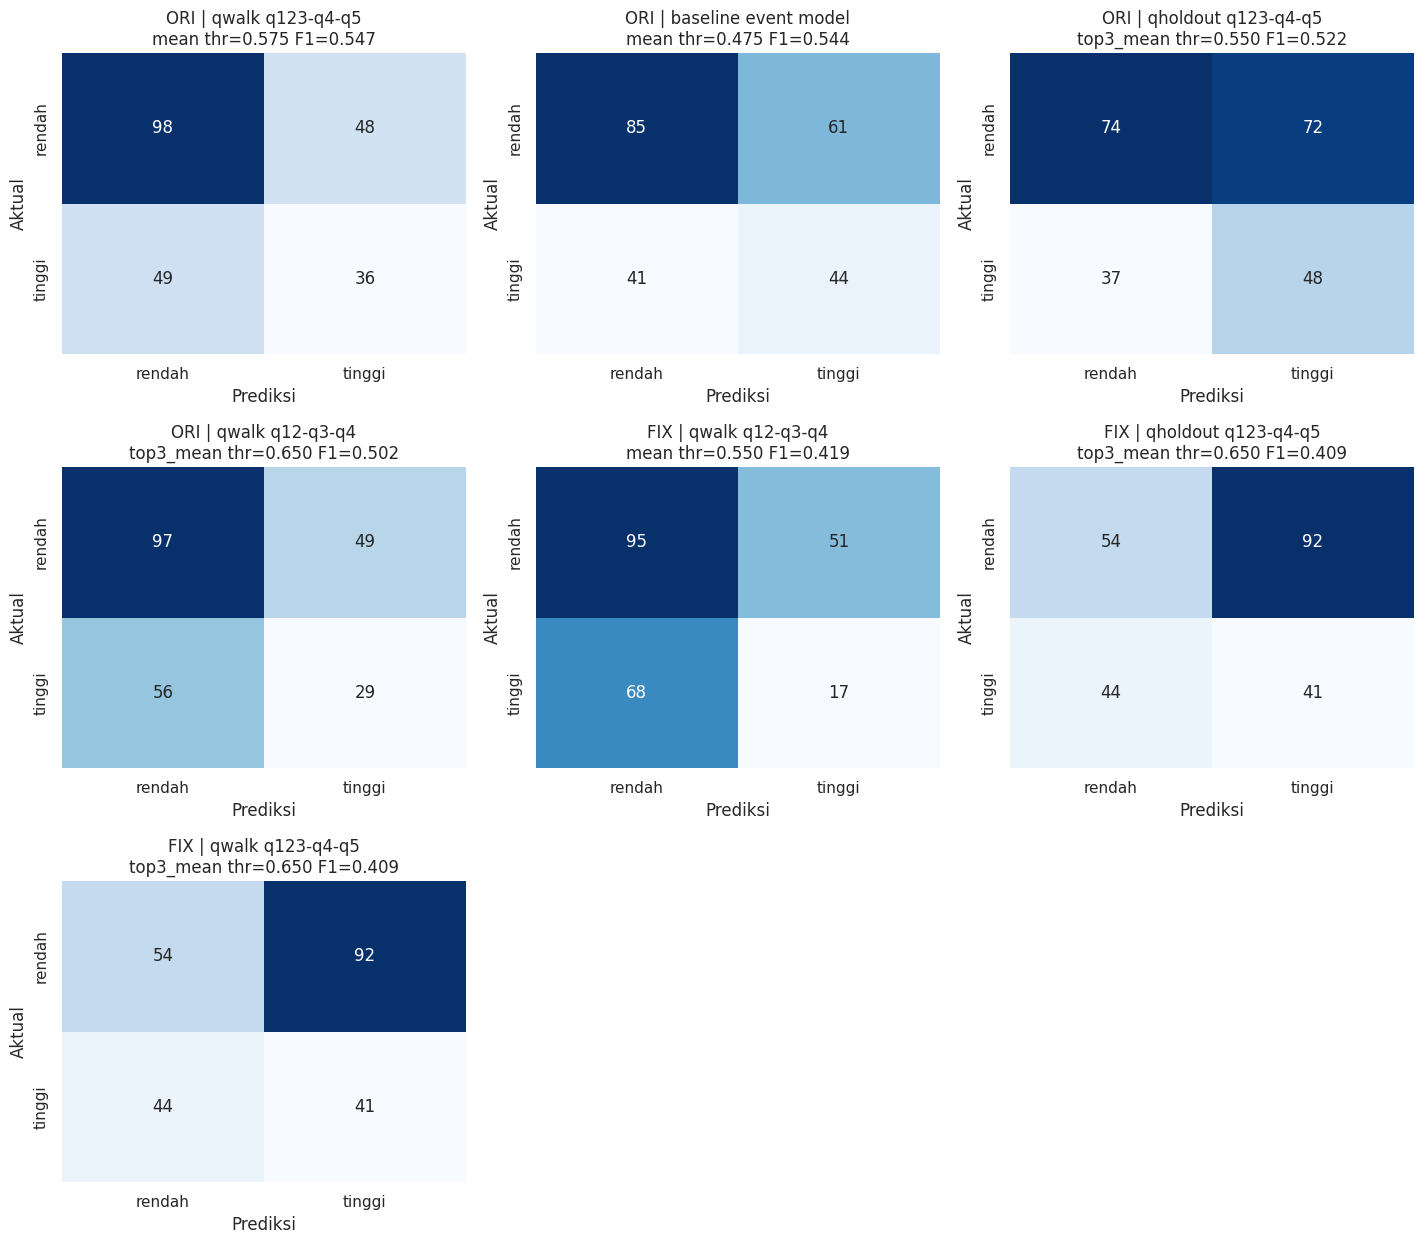

Saved grid: /home/ryuko/skripsi/Skripsi/Convat-1st/output/apex/datatest-fix/event_level_7models_report/confusion_matrices/confusion_matrix__best_all_models_grid.png


## ORI | qwalk q123-q4-q5 — `mean` threshold `0.575`

,model,variant,exp_name,mode,aggregation,threshold,n_events,tn,fp,fn,...,balanced_accuracy,precision_macro,recall_macro,macro_f1,precision_rendah,recall_rendah,f1_rendah,precision_tinggi,recall_tinggi,f1_tinggi
0,ORI | qwalk q123-q4-q5,original,convat_apex_anxiety_qwalk_q123_q4_q5,qwalkforward,mean,0.575,231,98,48,49,...,0.547381,0.547619,0.547381,0.547489,0.666667,0.671233,0.668942,0.428571,0.423529,0.426036


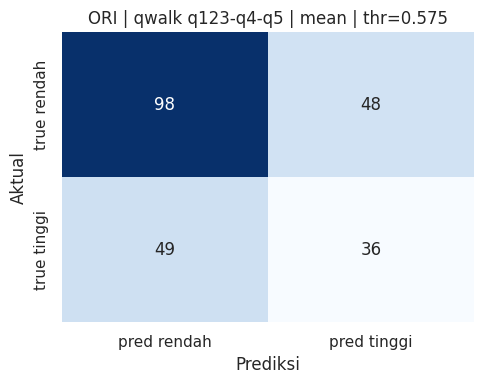

,No,Kode Event,Participant,Question,Label Aktual,Label Prediksi,Prob Tinggi,Jumlah Frame,Status
693,1,abim_mustawa_1776388618012 / q1 / event_00055-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_tinggi,0.594141,12,Benar
694,2,abim_mustawa_1776388618012 / q1 / event_00076-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_rendah,0.556318,18,Salah
695,3,abim_mustawa_1776388618012 / q1 / event_00130-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_rendah,0.513891,12,Salah
696,4,abim_mustawa_1776388618012 / q1 / event_00149-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_rendah,0.466584,20,Salah
697,5,abim_mustawa_1776388618012 / q1 / event_00295-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_rendah,0.455611,14,Salah
...,...,...,...,...,...,...,...,...,...
919,227,sileysa_faedatul_nuraini_1776227906081 / q4 / ...,sileysa_faedatul_nuraini_1776227906081,q4,anxiety_rendah,anxiety_rendah,0.214219,25,Benar
920,228,sileysa_faedatul_nuraini_1776227906081 / q4 / ...,sileysa_faedatul_nuraini_1776227906081,q4,anxiety_rendah,anxiety_tinggi,0.701161,11,Salah
921,229,sileysa_faedatul_nuraini_1776227906081 / q5 / ...,sileysa_faedatul_nuraini_1776227906081,q5,anxiety_rendah,anxiety_tinggi,0.679677,9,Salah
922,230,sileysa_faedatul_nuraini_1776227906081 / q5 / ...,sileysa_faedatul_nuraini_1776227906081,q5,anxiety_rendah,anxiety_tinggi,0.864516,11,Salah


## ORI | baseline event model — `mean` threshold `0.475`

,model,variant,exp_name,mode,aggregation,threshold,n_events,tn,fp,fn,...,balanced_accuracy,precision_macro,recall_macro,macro_f1,precision_rendah,recall_rendah,f1_rendah,precision_tinggi,recall_tinggi,f1_tinggi
1,ORI | baseline event model,original,convat_apex_anxiety,baseline,mean,0.475,231,85,61,41,...,0.549919,0.546825,0.549919,0.544079,0.674603,0.582192,0.625,0.419048,0.517647,0.463158


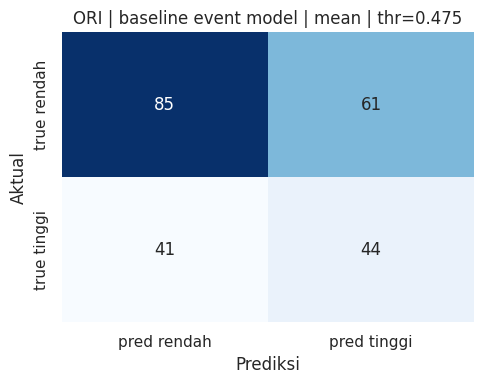

,No,Kode Event,Participant,Question,Label Aktual,Label Prediksi,Prob Tinggi,Jumlah Frame,Status
0,1,abim_mustawa_1776388618012 / q1 / event_00055-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_tinggi,0.635757,12,Benar
1,2,abim_mustawa_1776388618012 / q1 / event_00076-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_rendah,0.452655,18,Salah
2,3,abim_mustawa_1776388618012 / q1 / event_00130-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_rendah,0.228615,12,Salah
3,4,abim_mustawa_1776388618012 / q1 / event_00149-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_rendah,0.372470,20,Salah
4,5,abim_mustawa_1776388618012 / q1 / event_00295-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_tinggi,0.585594,14,Benar
...,...,...,...,...,...,...,...,...,...
226,227,sileysa_faedatul_nuraini_1776227906081 / q4 / ...,sileysa_faedatul_nuraini_1776227906081,q4,anxiety_rendah,anxiety_rendah,0.348054,25,Benar
227,228,sileysa_faedatul_nuraini_1776227906081 / q4 / ...,sileysa_faedatul_nuraini_1776227906081,q4,anxiety_rendah,anxiety_rendah,0.354538,11,Benar
228,229,sileysa_faedatul_nuraini_1776227906081 / q5 / ...,sileysa_faedatul_nuraini_1776227906081,q5,anxiety_rendah,anxiety_rendah,0.368787,9,Benar
229,230,sileysa_faedatul_nuraini_1776227906081 / q5 / ...,sileysa_faedatul_nuraini_1776227906081,q5,anxiety_rendah,anxiety_tinggi,0.715434,11,Salah


## ORI | qholdout q123-q4-q5 — `top3_mean` threshold `0.550`

,model,variant,exp_name,mode,aggregation,threshold,n_events,tn,fp,fn,...,balanced_accuracy,precision_macro,recall_macro,macro_f1,precision_rendah,recall_rendah,f1_rendah,precision_tinggi,recall_tinggi,f1_tinggi
2,ORI | qholdout q123-q4-q5,original,convat_apex_anxiety_qholdout_q123_q4_q5,qholdout,top3_mean,0.55,231,74,72,37,...,0.535778,0.533333,0.535778,0.522084,0.666667,0.506849,0.575875,0.4,0.564706,0.468293


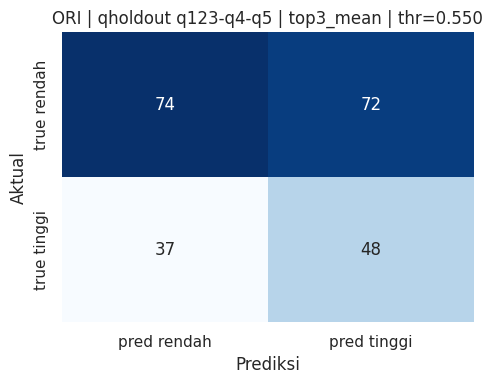

,No,Kode Event,Participant,Question,Label Aktual,Label Prediksi,Prob Tinggi,Jumlah Frame,Status
231,1,abim_mustawa_1776388618012 / q1 / event_00055-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_tinggi,0.876803,12,Benar
232,2,abim_mustawa_1776388618012 / q1 / event_00076-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_rendah,0.457562,18,Salah
233,3,abim_mustawa_1776388618012 / q1 / event_00130-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_rendah,0.497481,12,Salah
234,4,abim_mustawa_1776388618012 / q1 / event_00149-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_rendah,0.264480,20,Salah
235,5,abim_mustawa_1776388618012 / q1 / event_00295-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_tinggi,0.651845,14,Benar
...,...,...,...,...,...,...,...,...,...
457,227,sileysa_faedatul_nuraini_1776227906081 / q4 / ...,sileysa_faedatul_nuraini_1776227906081,q4,anxiety_rendah,anxiety_tinggi,0.567862,25,Salah
458,228,sileysa_faedatul_nuraini_1776227906081 / q4 / ...,sileysa_faedatul_nuraini_1776227906081,q4,anxiety_rendah,anxiety_tinggi,0.731481,11,Salah
459,229,sileysa_faedatul_nuraini_1776227906081 / q5 / ...,sileysa_faedatul_nuraini_1776227906081,q5,anxiety_rendah,anxiety_tinggi,0.705928,9,Salah
460,230,sileysa_faedatul_nuraini_1776227906081 / q5 / ...,sileysa_faedatul_nuraini_1776227906081,q5,anxiety_rendah,anxiety_tinggi,0.792148,11,Salah


## ORI | qwalk q12-q3-q4 — `top3_mean` threshold `0.650`

,model,variant,exp_name,mode,aggregation,threshold,n_events,tn,fp,fn,...,balanced_accuracy,precision_macro,recall_macro,macro_f1,precision_rendah,recall_rendah,f1_rendah,precision_tinggi,recall_tinggi,f1_tinggi
3,ORI | qwalk q12-q3-q4,original,convat_apex_anxiety_qwalk_q12_q3_q4,qwalkforward,top3_mean,0.65,231,97,49,56,...,0.50278,0.502891,0.50278,0.502329,0.633987,0.664384,0.648829,0.371795,0.341176,0.355828


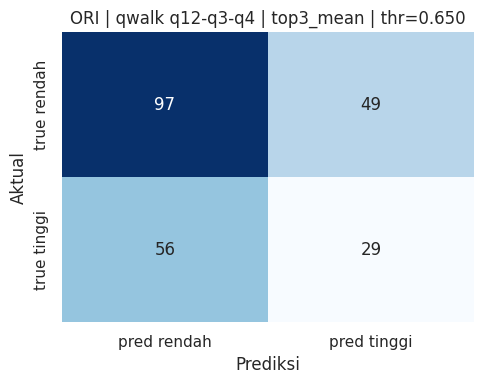

,No,Kode Event,Participant,Question,Label Aktual,Label Prediksi,Prob Tinggi,Jumlah Frame,Status
462,1,abim_mustawa_1776388618012 / q1 / event_00055-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_rendah,0.539337,12,Salah
463,2,abim_mustawa_1776388618012 / q1 / event_00076-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_tinggi,0.760770,18,Benar
464,3,abim_mustawa_1776388618012 / q1 / event_00130-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_rendah,0.354908,12,Salah
465,4,abim_mustawa_1776388618012 / q1 / event_00149-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_rendah,0.391133,20,Salah
466,5,abim_mustawa_1776388618012 / q1 / event_00295-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_tinggi,0.819878,14,Benar
...,...,...,...,...,...,...,...,...,...
688,227,sileysa_faedatul_nuraini_1776227906081 / q4 / ...,sileysa_faedatul_nuraini_1776227906081,q4,anxiety_rendah,anxiety_rendah,0.522440,25,Benar
689,228,sileysa_faedatul_nuraini_1776227906081 / q4 / ...,sileysa_faedatul_nuraini_1776227906081,q4,anxiety_rendah,anxiety_rendah,0.627577,11,Benar
690,229,sileysa_faedatul_nuraini_1776227906081 / q5 / ...,sileysa_faedatul_nuraini_1776227906081,q5,anxiety_rendah,anxiety_rendah,0.285427,9,Benar
691,230,sileysa_faedatul_nuraini_1776227906081 / q5 / ...,sileysa_faedatul_nuraini_1776227906081,q5,anxiety_rendah,anxiety_tinggi,0.660513,11,Salah


## FIX | qwalk q12-q3-q4 — `mean` threshold `0.550`

,model,variant,exp_name,mode,aggregation,threshold,n_events,tn,fp,fn,...,balanced_accuracy,precision_macro,recall_macro,macro_f1,precision_rendah,recall_rendah,f1_rendah,precision_tinggi,recall_tinggi,f1_tinggi
4,FIX | qwalk q12-q3-q4,fix,convat_apex_anxiety_qwalk_q12_q3_q4_fix,qwalkforward,mean,0.55,231,95,51,68,...,0.425342,0.416411,0.425342,0.418554,0.582822,0.650685,0.614887,0.25,0.2,0.222222


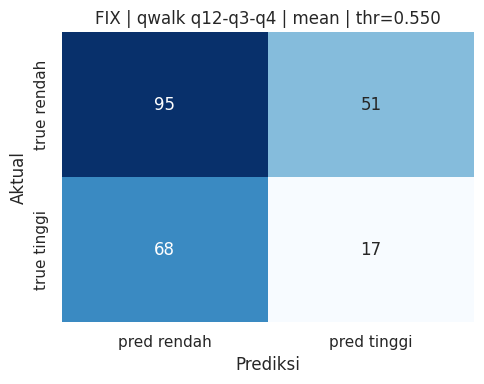

,No,Kode Event,Participant,Question,Label Aktual,Label Prediksi,Prob Tinggi,Jumlah Frame,Status
1155,1,abim_mustawa_1776388618012 / q1 / event_00055-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_rendah,0.410208,12,Salah
1156,2,abim_mustawa_1776388618012 / q1 / event_00076-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_rendah,0.307136,18,Salah
1157,3,abim_mustawa_1776388618012 / q1 / event_00130-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_rendah,0.535660,12,Salah
1158,4,abim_mustawa_1776388618012 / q1 / event_00149-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_rendah,0.506792,20,Salah
1159,5,abim_mustawa_1776388618012 / q1 / event_00295-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_rendah,0.434769,14,Salah
...,...,...,...,...,...,...,...,...,...
1381,227,sileysa_faedatul_nuraini_1776227906081 / q4 / ...,sileysa_faedatul_nuraini_1776227906081,q4,anxiety_rendah,anxiety_tinggi,0.667435,25,Salah
1382,228,sileysa_faedatul_nuraini_1776227906081 / q4 / ...,sileysa_faedatul_nuraini_1776227906081,q4,anxiety_rendah,anxiety_rendah,0.360593,11,Benar
1383,229,sileysa_faedatul_nuraini_1776227906081 / q5 / ...,sileysa_faedatul_nuraini_1776227906081,q5,anxiety_rendah,anxiety_rendah,0.469854,9,Benar
1384,230,sileysa_faedatul_nuraini_1776227906081 / q5 / ...,sileysa_faedatul_nuraini_1776227906081,q5,anxiety_rendah,anxiety_rendah,0.335123,11,Benar


## FIX | qholdout q123-q4-q5 — `top3_mean` threshold `0.650`

,model,variant,exp_name,mode,aggregation,threshold,n_events,tn,fp,fn,...,balanced_accuracy,precision_macro,recall_macro,macro_f1,precision_rendah,recall_rendah,f1_rendah,precision_tinggi,recall_tinggi,f1_tinggi
5,FIX | qholdout q123-q4-q5,fix,convat_apex_anxiety_qholdout_q123_q4_q5_fix,qholdout,top3_mean,0.65,231,54,92,44,...,0.426108,0.429646,0.426108,0.409385,0.55102,0.369863,0.442623,0.308271,0.482353,0.376147


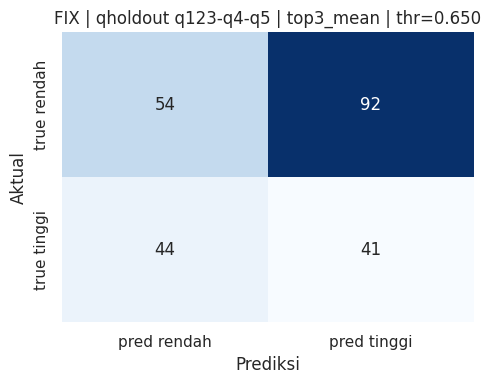

,No,Kode Event,Participant,Question,Label Aktual,Label Prediksi,Prob Tinggi,Jumlah Frame,Status
924,1,abim_mustawa_1776388618012 / q1 / event_00055-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_rendah,0.532458,12,Salah
925,2,abim_mustawa_1776388618012 / q1 / event_00076-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_rendah,0.595082,18,Salah
926,3,abim_mustawa_1776388618012 / q1 / event_00130-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_tinggi,0.710038,12,Benar
927,4,abim_mustawa_1776388618012 / q1 / event_00149-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_tinggi,0.790419,20,Benar
928,5,abim_mustawa_1776388618012 / q1 / event_00295-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_tinggi,0.703170,14,Benar
...,...,...,...,...,...,...,...,...,...
1150,227,sileysa_faedatul_nuraini_1776227906081 / q4 / ...,sileysa_faedatul_nuraini_1776227906081,q4,anxiety_rendah,anxiety_tinggi,0.846047,25,Salah
1151,228,sileysa_faedatul_nuraini_1776227906081 / q4 / ...,sileysa_faedatul_nuraini_1776227906081,q4,anxiety_rendah,anxiety_rendah,0.512572,11,Benar
1152,229,sileysa_faedatul_nuraini_1776227906081 / q5 / ...,sileysa_faedatul_nuraini_1776227906081,q5,anxiety_rendah,anxiety_rendah,0.455298,9,Benar
1153,230,sileysa_faedatul_nuraini_1776227906081 / q5 / ...,sileysa_faedatul_nuraini_1776227906081,q5,anxiety_rendah,anxiety_rendah,0.617840,11,Benar


## FIX | qwalk q123-q4-q5 — `top3_mean` threshold `0.650`

,model,variant,exp_name,mode,aggregation,threshold,n_events,tn,fp,fn,...,balanced_accuracy,precision_macro,recall_macro,macro_f1,precision_rendah,recall_rendah,f1_rendah,precision_tinggi,recall_tinggi,f1_tinggi
6,FIX | qwalk q123-q4-q5,fix,convat_apex_anxiety_qwalk_q123_q4_q5_fix,qwalkforward,top3_mean,0.65,231,54,92,44,...,0.426108,0.429646,0.426108,0.409385,0.55102,0.369863,0.442623,0.308271,0.482353,0.376147


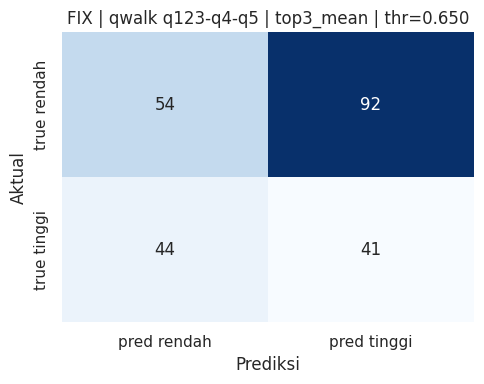

,No,Kode Event,Participant,Question,Label Aktual,Label Prediksi,Prob Tinggi,Jumlah Frame,Status
1386,1,abim_mustawa_1776388618012 / q1 / event_00055-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_rendah,0.532458,12,Salah
1387,2,abim_mustawa_1776388618012 / q1 / event_00076-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_rendah,0.595082,18,Salah
1388,3,abim_mustawa_1776388618012 / q1 / event_00130-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_tinggi,0.710038,12,Benar
1389,4,abim_mustawa_1776388618012 / q1 / event_00149-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_tinggi,0.790419,20,Benar
1390,5,abim_mustawa_1776388618012 / q1 / event_00295-...,abim_mustawa_1776388618012,q1,anxiety_tinggi,anxiety_tinggi,0.703170,14,Benar
...,...,...,...,...,...,...,...,...,...
1612,227,sileysa_faedatul_nuraini_1776227906081 / q4 / ...,sileysa_faedatul_nuraini_1776227906081,q4,anxiety_rendah,anxiety_tinggi,0.846047,25,Salah
1613,228,sileysa_faedatul_nuraini_1776227906081 / q4 / ...,sileysa_faedatul_nuraini_1776227906081,q4,anxiety_rendah,anxiety_rendah,0.512572,11,Benar
1614,229,sileysa_faedatul_nuraini_1776227906081 / q5 / ...,sileysa_faedatul_nuraini_1776227906081,q5,anxiety_rendah,anxiety_rendah,0.455298,9,Benar
1615,230,sileysa_faedatul_nuraini_1776227906081 / q5 / ...,sileysa_faedatul_nuraini_1776227906081,q5,anxiety_rendah,anxiety_rendah,0.617840,11,Benar


In [8]:
display(Markdown('# Global ranking — all aggregation + threshold candidates'))
global_rank_cols = ['model', 'variant', 'mode', 'aggregation', 'threshold', 'macro_f1', 'balanced_accuracy', 'accuracy', 'recall_tinggi', 'recall_rendah', 'tn', 'fp', 'fn', 'tp']
global_ranking_df = all_grid_summary_df.sort_values(PRIMARY_SORT, ascending=False).reset_index(drop=True)
global_ranking_df.insert(0, 'rank', np.arange(1, len(global_ranking_df) + 1))
display(global_ranking_df[['rank'] + global_rank_cols].head(50))

display(Markdown('# Best confusion matrices — all models'))
grid_path = plot_best_model_grid(best_predictions_df, best_metrics_df)
print(f'Saved grid: {grid_path}')

for _, row in best_metrics_df.iterrows():
    part = best_predictions_df[best_predictions_df['model_label'] == row['model']]
    path = CM_ROOT / f"confusion_matrix__{safe_name(row['model'])}__{row['aggregation']}__thr_{row['threshold']:.3f}.png"
    display(Markdown(f"## {row['model']} — `{row['aggregation']}` threshold `{row['threshold']:.3f}`"))
    display(pd.DataFrame([row]))
    plot_confusion(part, f"{row['model']} | {row['aggregation']} | thr={row['threshold']:.3f}", path)
    display(make_prediction_table(part))



# Subject-level inference — best setting per model

,model,variant,exp_name,mode,aggregation,threshold,n_subjects,tn,fp,fn,...,balanced_accuracy,precision_macro,recall_macro,macro_f1,precision_rendah,recall_rendah,f1_rendah,precision_tinggi,recall_tinggi,f1_tinggi
0,ORI | baseline event model,original,convat_apex_anxiety,baseline,mean,0.525,12,7,0,3,...,0.700000,0.850000,0.700000,0.697479,0.700000,1.000000,0.823529,1.000000,0.4,0.571429
1,ORI | qwalk q12-q3-q4,original,convat_apex_anxiety_qwalk_q12_q3_q4,qwalkforward,mean,0.575,12,5,2,2,...,0.657143,0.657143,0.657143,0.657143,0.714286,0.714286,0.714286,0.600000,0.6,0.600000
2,ORI | qholdout q123-q4-q5,original,convat_apex_anxiety_qholdout_q123_q4_q5,qholdout,mean,0.625,12,6,1,3,...,0.628571,0.666667,0.628571,0.625000,0.666667,0.857143,0.750000,0.666667,0.4,0.500000
3,ORI | qwalk q123-q4-q5,original,convat_apex_anxiety_qwalk_q123_q4_q5,qwalkforward,mean,0.450,12,3,4,1,...,0.614286,0.625000,0.614286,0.580420,0.750000,0.428571,0.545455,0.500000,0.8,0.615385
4,FIX | qholdout q123-q4-q5,fix,convat_apex_anxiety_qholdout_q123_q4_q5_fix,qholdout,mean,0.600,12,2,5,1,...,0.542857,0.555556,0.542857,0.485714,0.666667,0.285714,0.400000,0.444444,0.8,0.571429
5,FIX | qwalk q123-q4-q5,fix,convat_apex_anxiety_qwalk_q123_q4_q5_fix,qwalkforward,mean,0.600,12,2,5,1,...,0.542857,0.555556,0.542857,0.485714,0.666667,0.285714,0.400000,0.444444,0.8,0.571429
6,FIX | qwalk q12-q3-q4,fix,convat_apex_anxiety_qwalk_q12_q3_q4_fix,qwalkforward,mean,0.425,12,1,6,1,...,0.471429,0.450000,0.471429,0.377778,0.500000,0.142857,0.222222,0.400000,0.8,0.533333


# Subject-level global ranking

,rank,model,variant,mode,aggregation,threshold,macro_f1,balanced_accuracy,accuracy,recall_tinggi,recall_rendah,tn,fp,fn,tp
0,1,ORI | baseline event model,original,baseline,mean,0.525,0.697479,0.700000,0.750000,0.4,1.000000,7,0,3,2
1,2,ORI | baseline event model,original,baseline,mean,0.550,0.697479,0.700000,0.750000,0.4,1.000000,7,0,3,2
2,3,ORI | baseline event model,original,baseline,mean,0.575,0.697479,0.700000,0.750000,0.4,1.000000,7,0,3,2
3,4,ORI | qwalk q12-q3-q4,original,qwalkforward,mean,0.575,0.657143,0.657143,0.666667,0.6,0.714286,5,2,2,3
4,5,ORI | baseline event model,original,baseline,mean,0.500,0.625000,0.628571,0.666667,0.4,0.857143,6,1,3,2
5,6,ORI | qholdout q123-q4-q5,original,qholdout,mean,0.625,0.625000,0.628571,0.666667,0.4,0.857143,6,1,3,2
6,7,ORI | qholdout q123-q4-q5,original,qholdout,mean,0.650,0.625000,0.628571,0.666667,0.4,0.857143,6,1,3,2
7,8,ORI | qwalk q123-q4-q5,original,qwalkforward,mean,0.450,0.580420,0.614286,0.583333,0.8,0.428571,3,4,1,4
8,9,ORI | qwalk q123-q4-q5,original,qwalkforward,mean,0.475,0.580420,0.614286,0.583333,0.8,0.428571,3,4,1,4
9,10,ORI | qwalk q123-q4-q5,original,qwalkforward,mean,0.500,0.580420,0.585714,0.583333,0.6,0.571429,4,3,2,3


## Subject ORI | baseline event model — `mean` threshold `0.525`

,model,variant,exp_name,mode,aggregation,threshold,n_subjects,tn,fp,fn,...,balanced_accuracy,precision_macro,recall_macro,macro_f1,precision_rendah,recall_rendah,f1_rendah,precision_tinggi,recall_tinggi,f1_tinggi
0,ORI | baseline event model,original,convat_apex_anxiety,baseline,mean,0.525,12,7,0,3,...,0.7,0.85,0.7,0.697479,0.7,1.0,0.823529,1.0,0.4,0.571429


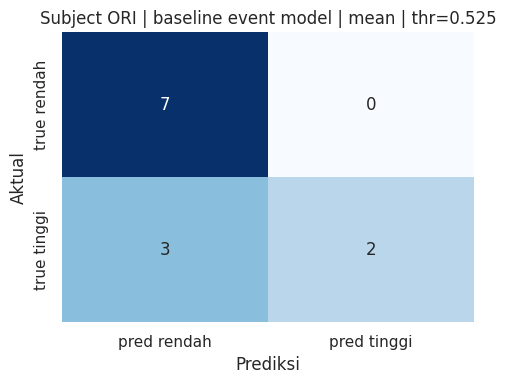

,No,participant_base,Label Aktual,Label Prediksi,Status,subject_prob_anxiety_tinggi,n_events,n_frames
0,1,abim_mustawa,anxiety_tinggi,anxiety_tinggi,Benar,0.575188,18,259
1,2,ahmad_falahi,anxiety_tinggi,anxiety_tinggi,Benar,0.589482,15,165
2,3,aryan_zuda_firdaus,anxiety_rendah,anxiety_rendah,Benar,0.488234,23,201
3,4,dewi_anggraini_meita_sari,anxiety_rendah,anxiety_rendah,Benar,0.438508,15,125
4,5,dicky_darmawan,anxiety_tinggi,anxiety_rendah,Salah,0.333489,19,326
5,6,ilham_dharma_atmaja,anxiety_rendah,anxiety_rendah,Benar,0.523697,20,271
6,7,muhammad_christiano_olyvian_barini,anxiety_rendah,anxiety_rendah,Benar,0.374822,25,311
7,8,muhammad_daniel_assaqovi,anxiety_rendah,anxiety_rendah,Benar,0.432788,23,305
8,9,muhammad_nuril_huda,anxiety_tinggi,anxiety_rendah,Salah,0.416183,15,170
9,10,naufal_ramadhan_wahyudiansyah,anxiety_tinggi,anxiety_rendah,Salah,0.363489,18,217


## Subject ORI | qwalk q12-q3-q4 — `mean` threshold `0.575`

,model,variant,exp_name,mode,aggregation,threshold,n_subjects,tn,fp,fn,...,balanced_accuracy,precision_macro,recall_macro,macro_f1,precision_rendah,recall_rendah,f1_rendah,precision_tinggi,recall_tinggi,f1_tinggi
1,ORI | qwalk q12-q3-q4,original,convat_apex_anxiety_qwalk_q12_q3_q4,qwalkforward,mean,0.575,12,5,2,2,...,0.657143,0.657143,0.657143,0.657143,0.714286,0.714286,0.714286,0.6,0.6,0.6


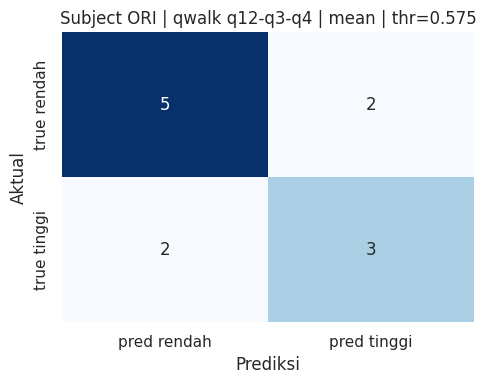

,No,participant_base,Label Aktual,Label Prediksi,Status,subject_prob_anxiety_tinggi,n_events,n_frames
24,1,abim_mustawa,anxiety_tinggi,anxiety_tinggi,Benar,0.618959,18,259
25,2,ahmad_falahi,anxiety_tinggi,anxiety_tinggi,Benar,0.580426,15,165
26,3,aryan_zuda_firdaus,anxiety_rendah,anxiety_rendah,Benar,0.515673,23,201
27,4,dewi_anggraini_meita_sari,anxiety_rendah,anxiety_rendah,Benar,0.545008,15,125
28,5,dicky_darmawan,anxiety_tinggi,anxiety_tinggi,Benar,0.583075,19,326
29,6,ilham_dharma_atmaja,anxiety_rendah,anxiety_tinggi,Salah,0.600326,20,271
30,7,muhammad_christiano_olyvian_barini,anxiety_rendah,anxiety_tinggi,Salah,0.586806,25,311
31,8,muhammad_daniel_assaqovi,anxiety_rendah,anxiety_rendah,Benar,0.559910,23,305
32,9,muhammad_nuril_huda,anxiety_tinggi,anxiety_rendah,Salah,0.459732,15,170
33,10,naufal_ramadhan_wahyudiansyah,anxiety_tinggi,anxiety_rendah,Salah,0.460450,18,217


## Subject ORI | qholdout q123-q4-q5 — `mean` threshold `0.625`

,model,variant,exp_name,mode,aggregation,threshold,n_subjects,tn,fp,fn,...,balanced_accuracy,precision_macro,recall_macro,macro_f1,precision_rendah,recall_rendah,f1_rendah,precision_tinggi,recall_tinggi,f1_tinggi
2,ORI | qholdout q123-q4-q5,original,convat_apex_anxiety_qholdout_q123_q4_q5,qholdout,mean,0.625,12,6,1,3,...,0.628571,0.666667,0.628571,0.625,0.666667,0.857143,0.75,0.666667,0.4,0.5


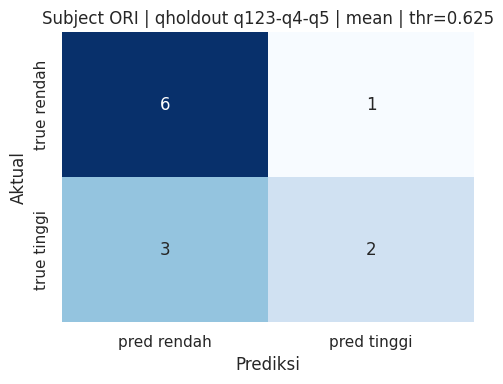

,No,participant_base,Label Aktual,Label Prediksi,Status,subject_prob_anxiety_tinggi,n_events,n_frames
12,1,abim_mustawa,anxiety_tinggi,anxiety_tinggi,Benar,0.653220,18,259
13,2,ahmad_falahi,anxiety_tinggi,anxiety_tinggi,Benar,0.656007,15,165
14,3,aryan_zuda_firdaus,anxiety_rendah,anxiety_rendah,Benar,0.433759,23,201
15,4,dewi_anggraini_meita_sari,anxiety_rendah,anxiety_rendah,Benar,0.550380,15,125
16,5,dicky_darmawan,anxiety_tinggi,anxiety_rendah,Salah,0.486612,19,326
17,6,ilham_dharma_atmaja,anxiety_rendah,anxiety_tinggi,Salah,0.739940,20,271
18,7,muhammad_christiano_olyvian_barini,anxiety_rendah,anxiety_rendah,Benar,0.613234,25,311
19,8,muhammad_daniel_assaqovi,anxiety_rendah,anxiety_rendah,Benar,0.497227,23,305
20,9,muhammad_nuril_huda,anxiety_tinggi,anxiety_rendah,Salah,0.472963,15,170
21,10,naufal_ramadhan_wahyudiansyah,anxiety_tinggi,anxiety_rendah,Salah,0.500147,18,217


## Subject ORI | qwalk q123-q4-q5 — `mean` threshold `0.450`

,model,variant,exp_name,mode,aggregation,threshold,n_subjects,tn,fp,fn,...,balanced_accuracy,precision_macro,recall_macro,macro_f1,precision_rendah,recall_rendah,f1_rendah,precision_tinggi,recall_tinggi,f1_tinggi
3,ORI | qwalk q123-q4-q5,original,convat_apex_anxiety_qwalk_q123_q4_q5,qwalkforward,mean,0.45,12,3,4,1,...,0.614286,0.625,0.614286,0.58042,0.75,0.428571,0.545455,0.5,0.8,0.615385


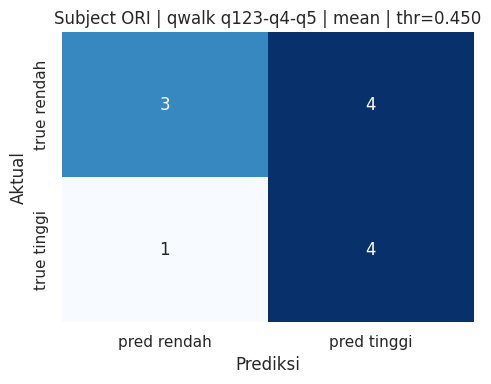

,No,participant_base,Label Aktual,Label Prediksi,Status,subject_prob_anxiety_tinggi,n_events,n_frames
36,1,abim_mustawa,anxiety_tinggi,anxiety_tinggi,Benar,0.596044,18,259
37,2,ahmad_falahi,anxiety_tinggi,anxiety_tinggi,Benar,0.628445,15,165
38,3,aryan_zuda_firdaus,anxiety_rendah,anxiety_rendah,Benar,0.449483,23,201
39,4,dewi_anggraini_meita_sari,anxiety_rendah,anxiety_tinggi,Salah,0.571200,15,125
40,5,dicky_darmawan,anxiety_tinggi,anxiety_rendah,Salah,0.404323,19,326
41,6,ilham_dharma_atmaja,anxiety_rendah,anxiety_tinggi,Salah,0.624608,20,271
42,7,muhammad_christiano_olyvian_barini,anxiety_rendah,anxiety_rendah,Benar,0.389204,25,311
43,8,muhammad_daniel_assaqovi,anxiety_rendah,anxiety_rendah,Benar,0.447312,23,305
44,9,muhammad_nuril_huda,anxiety_tinggi,anxiety_tinggi,Benar,0.512167,15,170
45,10,naufal_ramadhan_wahyudiansyah,anxiety_tinggi,anxiety_tinggi,Benar,0.499354,18,217


## Subject FIX | qholdout q123-q4-q5 — `mean` threshold `0.600`

,model,variant,exp_name,mode,aggregation,threshold,n_subjects,tn,fp,fn,...,balanced_accuracy,precision_macro,recall_macro,macro_f1,precision_rendah,recall_rendah,f1_rendah,precision_tinggi,recall_tinggi,f1_tinggi
4,FIX | qholdout q123-q4-q5,fix,convat_apex_anxiety_qholdout_q123_q4_q5_fix,qholdout,mean,0.6,12,2,5,1,...,0.542857,0.555556,0.542857,0.485714,0.666667,0.285714,0.4,0.444444,0.8,0.571429


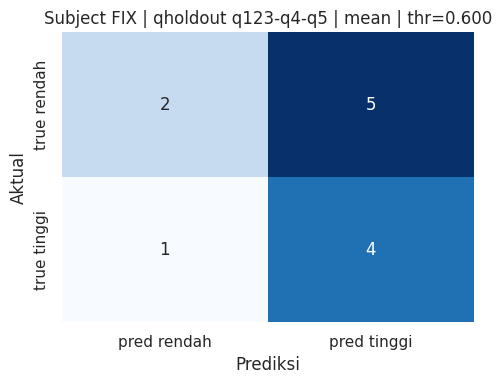

,No,participant_base,Label Aktual,Label Prediksi,Status,subject_prob_anxiety_tinggi,n_events,n_frames
48,1,abim_mustawa,anxiety_tinggi,anxiety_tinggi,Benar,0.688711,18,259
49,2,ahmad_falahi,anxiety_tinggi,anxiety_tinggi,Benar,0.616754,15,165
50,3,aryan_zuda_firdaus,anxiety_rendah,anxiety_tinggi,Salah,0.665224,23,201
51,4,dewi_anggraini_meita_sari,anxiety_rendah,anxiety_rendah,Benar,0.574636,15,125
52,5,dicky_darmawan,anxiety_tinggi,anxiety_tinggi,Benar,0.649682,19,326
53,6,ilham_dharma_atmaja,anxiety_rendah,anxiety_rendah,Benar,0.595046,20,271
54,7,muhammad_christiano_olyvian_barini,anxiety_rendah,anxiety_tinggi,Salah,0.750398,25,311
55,8,muhammad_daniel_assaqovi,anxiety_rendah,anxiety_tinggi,Salah,0.735382,23,305
56,9,muhammad_nuril_huda,anxiety_tinggi,anxiety_rendah,Salah,0.591184,15,170
57,10,naufal_ramadhan_wahyudiansyah,anxiety_tinggi,anxiety_tinggi,Benar,0.604082,18,217


## Subject FIX | qwalk q123-q4-q5 — `mean` threshold `0.600`

,model,variant,exp_name,mode,aggregation,threshold,n_subjects,tn,fp,fn,...,balanced_accuracy,precision_macro,recall_macro,macro_f1,precision_rendah,recall_rendah,f1_rendah,precision_tinggi,recall_tinggi,f1_tinggi
5,FIX | qwalk q123-q4-q5,fix,convat_apex_anxiety_qwalk_q123_q4_q5_fix,qwalkforward,mean,0.6,12,2,5,1,...,0.542857,0.555556,0.542857,0.485714,0.666667,0.285714,0.4,0.444444,0.8,0.571429


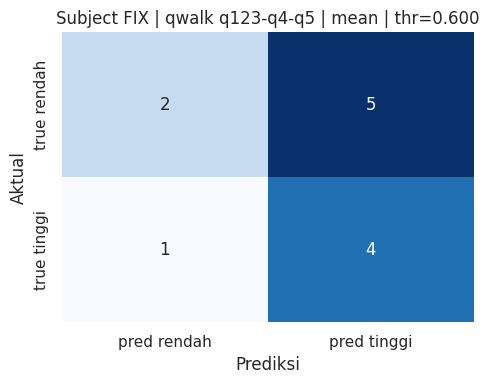

,No,participant_base,Label Aktual,Label Prediksi,Status,subject_prob_anxiety_tinggi,n_events,n_frames
72,1,abim_mustawa,anxiety_tinggi,anxiety_tinggi,Benar,0.688711,18,259
73,2,ahmad_falahi,anxiety_tinggi,anxiety_tinggi,Benar,0.616754,15,165
74,3,aryan_zuda_firdaus,anxiety_rendah,anxiety_tinggi,Salah,0.665224,23,201
75,4,dewi_anggraini_meita_sari,anxiety_rendah,anxiety_rendah,Benar,0.574636,15,125
76,5,dicky_darmawan,anxiety_tinggi,anxiety_tinggi,Benar,0.649682,19,326
77,6,ilham_dharma_atmaja,anxiety_rendah,anxiety_rendah,Benar,0.595046,20,271
78,7,muhammad_christiano_olyvian_barini,anxiety_rendah,anxiety_tinggi,Salah,0.750398,25,311
79,8,muhammad_daniel_assaqovi,anxiety_rendah,anxiety_tinggi,Salah,0.735382,23,305
80,9,muhammad_nuril_huda,anxiety_tinggi,anxiety_rendah,Salah,0.591184,15,170
81,10,naufal_ramadhan_wahyudiansyah,anxiety_tinggi,anxiety_tinggi,Benar,0.604082,18,217


## Subject FIX | qwalk q12-q3-q4 — `mean` threshold `0.425`

,model,variant,exp_name,mode,aggregation,threshold,n_subjects,tn,fp,fn,...,balanced_accuracy,precision_macro,recall_macro,macro_f1,precision_rendah,recall_rendah,f1_rendah,precision_tinggi,recall_tinggi,f1_tinggi
6,FIX | qwalk q12-q3-q4,fix,convat_apex_anxiety_qwalk_q12_q3_q4_fix,qwalkforward,mean,0.425,12,1,6,1,...,0.471429,0.45,0.471429,0.377778,0.5,0.142857,0.222222,0.4,0.8,0.533333


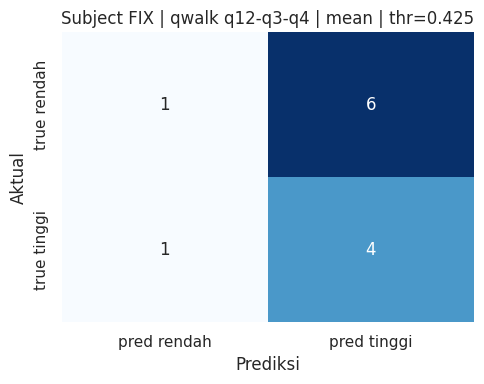

,No,participant_base,Label Aktual,Label Prediksi,Status,subject_prob_anxiety_tinggi,n_events,n_frames
60,1,abim_mustawa,anxiety_tinggi,anxiety_rendah,Salah,0.419835,18,259
61,2,ahmad_falahi,anxiety_tinggi,anxiety_tinggi,Benar,0.450277,15,165
62,3,aryan_zuda_firdaus,anxiety_rendah,anxiety_tinggi,Salah,0.554645,23,201
63,4,dewi_anggraini_meita_sari,anxiety_rendah,anxiety_tinggi,Salah,0.471572,15,125
64,5,dicky_darmawan,anxiety_tinggi,anxiety_tinggi,Benar,0.455484,19,326
65,6,ilham_dharma_atmaja,anxiety_rendah,anxiety_rendah,Benar,0.422721,20,271
66,7,muhammad_christiano_olyvian_barini,anxiety_rendah,anxiety_tinggi,Salah,0.556791,25,311
67,8,muhammad_daniel_assaqovi,anxiety_rendah,anxiety_tinggi,Salah,0.534990,23,305
68,9,muhammad_nuril_huda,anxiety_tinggi,anxiety_tinggi,Benar,0.459584,15,170
69,10,naufal_ramadhan_wahyudiansyah,anxiety_tinggi,anxiety_tinggi,Benar,0.522913,18,217


In [9]:
def make_subject_predictions(event_prediction_df: pd.DataFrame, spec: dict, method: str, threshold: float) -> pd.DataFrame:
    rows = []
    for _participant, g in event_prediction_df.groupby('participant_base', sort=False):
        first = g.iloc[0]
        prob = aggregate_probs(g['agg_prob_anxiety_tinggi'], method)
        true_label = int(g['true_label'].mode().iloc[0])
        rows.append({
            'participant_base': first['participant_base'],
            'model_label': spec['label'],
            'exp_name': spec['exp_name'],
            'mode': spec['mode'],
            'aggregation': method,
            'threshold': float(threshold),
            'subject_prob_anxiety_tinggi': prob,
            'true_label': true_label,
            'pred_label': int(prob >= threshold),
            'n_events': len(g),
            'n_frames': int(g['n_frames'].sum()),
        })
    return pd.DataFrame(rows)


def evaluate_subject_grid(event_prediction_df: pd.DataFrame, spec: dict) -> tuple[pd.DataFrame, dict]:
    rows, predictions = [], {}
    for method in EVENT_METHODS:
        for threshold in THRESHOLDS:
            pred = make_subject_predictions(event_prediction_df, spec, method, threshold)
            predictions[(method, float(threshold))] = pred
            y_true = pred['true_label'].astype(int).to_numpy()
            y_pred = pred['pred_label'].astype(int).to_numpy()
            tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
            precision_macro, recall_macro, macro_f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
            per_prec, per_rec, per_f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1], zero_division=0)
            rows.append({
                'model': spec['label'], 'variant': spec.get('variant', ''), 'exp_name': spec['exp_name'], 'mode': spec['mode'],
                'aggregation': method, 'threshold': float(threshold), 'n_subjects': len(pred),
                'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
                'accuracy': float(accuracy_score(y_true, y_pred)),
                'balanced_accuracy': float(balanced_accuracy_score(y_true, y_pred)),
                'precision_macro': float(precision_macro), 'recall_macro': float(recall_macro), 'macro_f1': float(macro_f1),
                'precision_rendah': float(per_prec[0]), 'recall_rendah': float(per_rec[0]), 'f1_rendah': float(per_f1[0]),
                'precision_tinggi': float(per_prec[1]), 'recall_tinggi': float(per_rec[1]), 'f1_tinggi': float(per_f1[1]),
            })
    return pd.DataFrame(rows), predictions


subject_results = []
for result in results:
    spec = result['spec']
    event_grid_df, event_lookup = evaluate_grid(result['frame_predictions'], spec)
    best_event = choose_best(event_grid_df)
    event_pred = event_lookup[(best_event['aggregation'], float(best_event['threshold']))].copy()
    subject_grid_df, subject_lookup = evaluate_subject_grid(event_pred, spec)
    best_subject = choose_best(subject_grid_df)
    subject_pred = subject_lookup[(best_subject['aggregation'], float(best_subject['threshold']))].copy()
    subject_results.append({
        'spec': spec,
        'subject_grid_df': subject_grid_df,
        'best_subject': best_subject.to_dict(),
        'subject_prediction_df': subject_pred,
        'event_best_for_subject': best_event.to_dict(),
    })

subject_grid_summary_df = pd.concat([r['subject_grid_df'] for r in subject_results], ignore_index=True)
best_subject_metrics_df = pd.DataFrame([r['best_subject'] for r in subject_results]).sort_values(PRIMARY_SORT, ascending=False).reset_index(drop=True)
best_subject_predictions_df = pd.concat([r['subject_prediction_df'] for r in subject_results], ignore_index=True)

display(Markdown('# Subject-level inference — best setting per model'))
display(best_subject_metrics_df)

display(Markdown('# Subject-level global ranking'))
subject_global_ranking_df = subject_grid_summary_df.sort_values(PRIMARY_SORT, ascending=False).reset_index(drop=True)
subject_global_ranking_df.insert(0, 'rank', np.arange(1, len(subject_global_ranking_df) + 1))
subject_rank_cols = ['model', 'variant', 'mode', 'aggregation', 'threshold', 'macro_f1', 'balanced_accuracy', 'accuracy', 'recall_tinggi', 'recall_rendah', 'tn', 'fp', 'fn', 'tp']
display(subject_global_ranking_df[['rank'] + subject_rank_cols].head(50))

for _, row in best_subject_metrics_df.iterrows():
    part = best_subject_predictions_df[best_subject_predictions_df['model_label'] == row['model']]
    path = CM_ROOT / f"subject_confusion_matrix__{safe_name(row['model'])}__{row['aggregation']}__thr_{row['threshold']:.3f}.png"
    display(Markdown(f"## Subject {row['model']} — `{row['aggregation']}` threshold `{row['threshold']:.3f}`"))
    display(pd.DataFrame([row]))
    plot_confusion(part, f"Subject {row['model']} | {row['aggregation']} | thr={row['threshold']:.3f}", path)
    table = part[['participant_base', 'true_label', 'pred_label', 'subject_prob_anxiety_tinggi', 'n_events', 'n_frames']].copy()
    table.insert(0, 'No', np.arange(1, len(table) + 1))
    table['Label Aktual'] = table['true_label'].map(int_to_label)
    table['Label Prediksi'] = table['pred_label'].map(int_to_label)
    table['Status'] = np.where(table['true_label'] == table['pred_label'], 'Benar', 'Salah')
    display(table[['No', 'participant_base', 'Label Aktual', 'Label Prediksi', 'Status', 'subject_prob_anxiety_tinggi', 'n_events', 'n_frames']])


In [11]:
artifacts = {
    'event_overview': EVAL_ROOT / 'event_overview.xlsx',
    'all_grid_summary': EVAL_ROOT / 'all_grid_summary.xlsx',
    'global_ranking': EVAL_ROOT / 'global_ranking.xlsx',
    'best_metrics': EVAL_ROOT / 'best_metrics.xlsx',
    'best_predictions': EVAL_ROOT / 'best_predictions.xlsx',
    'frame_predictions': EVAL_ROOT / 'frame_predictions.xlsx',
    'subject_grid_summary': EVAL_ROOT / 'subject_grid_summary.xlsx',
    'subject_global_ranking': EVAL_ROOT / 'subject_global_ranking.xlsx',
    'best_subject_metrics': EVAL_ROOT / 'best_subject_metrics.xlsx',
    'best_subject_predictions': EVAL_ROOT / 'best_subject_predictions.xlsx',
}
event_overview_df.to_excel(artifacts['event_overview'], index=False)
all_grid_summary_df.to_excel(artifacts['all_grid_summary'], index=False)
global_ranking_df.to_excel(artifacts['global_ranking'], index=False)
best_metrics_df.to_excel(artifacts['best_metrics'], index=False)
best_predictions_df.to_excel(artifacts['best_predictions'], index=False)
frame_predictions_df.to_excel(artifacts['frame_predictions'], index=False)
subject_grid_summary_df.to_excel(artifacts['subject_grid_summary'], index=False)
subject_global_ranking_df.to_excel(artifacts['subject_global_ranking'], index=False)
best_subject_metrics_df.to_excel(artifacts['best_subject_metrics'], index=False)
best_subject_predictions_df.to_excel(artifacts['best_subject_predictions'], index=False)

for name, path in artifacts.items():
    print(f'{name}: {path}')


event_overview: /home/ryuko/skripsi/Skripsi/Convat-1st/output/apex/datatest-fix/event_level_7models_report/event_overview.xlsx
all_grid_summary: /home/ryuko/skripsi/Skripsi/Convat-1st/output/apex/datatest-fix/event_level_7models_report/all_grid_summary.xlsx
global_ranking: /home/ryuko/skripsi/Skripsi/Convat-1st/output/apex/datatest-fix/event_level_7models_report/global_ranking.xlsx
best_metrics: /home/ryuko/skripsi/Skripsi/Convat-1st/output/apex/datatest-fix/event_level_7models_report/best_metrics.xlsx
best_predictions: /home/ryuko/skripsi/Skripsi/Convat-1st/output/apex/datatest-fix/event_level_7models_report/best_predictions.xlsx
frame_predictions: /home/ryuko/skripsi/Skripsi/Convat-1st/output/apex/datatest-fix/event_level_7models_report/frame_predictions.xlsx
subject_grid_summary: /home/ryuko/skripsi/Skripsi/Convat-1st/output/apex/datatest-fix/event_level_7models_report/subject_grid_summary.xlsx
subject_global_ranking: /home/ryuko/skripsi/Skripsi/Convat-1st/output/apex/datatest-fix/e